# VGG16 — Amazonian Geoglyph Detection
**Model 5 of 7 — Phase 1 Classical Benchmark**

VGG16 is the oldest architecture in our benchmark (2014, Oxford VGG group).
13 convolutional layers, all 3×3 filters, simple sequential design — no skip connections,
no dense connectivity, no squeeze-excitation. Just deep stacked convolutions.

Key facts:
- ~138M total parameters (by far the largest model we test)
- 512-dim GAP output (smallest of all models)
- 224×224 input — same as B0, MobileNetV3, DenseNet
- Built-in preprocessing — NO manual rescaling needed (like EfficientNet)
- Expect significant overfitting — 138M params vs 371 positives is extreme mismatch
- Still valuable: classic baseline that reviewers expect in any CNN comparison paper

In [1]:
import os
from google.colab import drive
drive.mount('/content/drive')

POS_DIR = "/content/drive/MyDrive/ArchP/binary_dataset/positive"
NEG_DIR = "/content/drive/MyDrive/ArchP/binary_dataset/negative"
VALID_EXT = {'.jpg', '.jpeg', '.png', '.tif', '.tiff'}

def count_images(folder_path):
    files = [f for f in os.listdir(folder_path)
             if os.path.splitext(f)[1].lower() in VALID_EXT]
    return len(files)

n_pos = count_images(POS_DIR)
n_neg = count_images(NEG_DIR)
print(f"Positive: {n_pos} | Negative: {n_neg} | Total: {n_pos + n_neg}")
print("Drive mounted OK")

Mounted at /content/drive
Positive: 530 | Negative: 2181 | Total: 2711
Drive mounted OK


## Step 1 — Imports & Seeds
VGG16 imported from keras.applications.
Same SEED=42 across all 7 models.

In [2]:
import os, random, numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import VGG16
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from pathlib import Path

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TF:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TF: 2.19.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 2 — Splits & Class Weights
Identical to all previous models.
IMG_SIZE stays at 224 — VGG16 standard input resolution.

In [3]:
POS_DIR    = "/content/drive/MyDrive/ArchP/binary_dataset/positive"
NEG_DIR    = "/content/drive/MyDrive/ArchP/binary_dataset/negative"
OUTPUT_DIR = "/content/outputs"
IMG_SIZE   = 224
BATCH_SIZE = 32

VALID_EXT = {'.jpg', '.jpeg', '.png', '.tif', '.tiff'}
os.makedirs(OUTPUT_DIR, exist_ok=True)

pos_files = [(str(p), 1) for p in sorted(Path(POS_DIR).iterdir())
             if p.suffix.lower() in VALID_EXT]
neg_files = [(str(p), 0) for p in sorted(Path(NEG_DIR).iterdir())
             if p.suffix.lower() in VALID_EXT]

df = pd.DataFrame(pos_files + neg_files, columns=['filepath', 'label'])

train_val_df, test_df = train_test_split(
    df, test_size=0.15, stratify=df['label'], random_state=SEED)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.176, stratify=train_val_df['label'], random_state=SEED)

train_df = train_df.copy(); train_df['split'] = 'train'
val_df   = val_df.copy();   val_df['split']   = 'val'
test_df  = test_df.copy();  test_df['split']  = 'test'

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=train_df['label'].values)
class_weight_dict = {0: class_weights[0], 1: class_weights[1]}

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print(f"Class weights -> Neg: {class_weight_dict[0]:.4f} | Pos: {class_weight_dict[1]:.4f}")
print(f"IMG_SIZE: {IMG_SIZE} | BATCH_SIZE: {BATCH_SIZE}")

Train: 1898 | Val: 406 | Test: 407
Class weights -> Neg: 0.6215 | Pos: 2.5580
IMG_SIZE: 224 | BATCH_SIZE: 32


## Step 3 — Build tf.data Datasets
Same pipeline as all previous models.
VGG16 has built-in preprocessing like EfficientNet — pass raw [0,255] pixels,
NO manual Rescaling or Lambda layer needed.
ignore_errors() handles the known corrupt PNG.

In [4]:
def load_and_preprocess(filepath, label):
    raw   = tf.io.read_file(filepath)
    image = tf.image.decode_image(raw, channels=3, expand_animations=False)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)  # keep [0,255] — VGG16 normalizes internally
    return image, tf.cast(label, tf.float32)

def build_dataset(dataframe, shuffle=False):
    filepaths = dataframe['filepath'].values
    labels    = dataframe['label'].values.astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe), seed=SEED,
                        reshuffle_each_iteration=True)
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.ignore_errors()   # skips the known corrupt PNG silently
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = build_dataset(train_df, shuffle=True)
val_ds   = build_dataset(val_df,   shuffle=False)
test_ds  = build_dataset(test_df,  shuffle=False)

print("Datasets built — 224x224 px, ignore_errors active")
print(f"Train batches: {len(train_df)//BATCH_SIZE} | "
      f"Val batches: {len(val_df)//BATCH_SIZE} | "
      f"Test batches: {len(test_df)//BATCH_SIZE}")

Datasets built — 224x224 px, ignore_errors active
Train batches: 59 | Val batches: 12 | Test batches: 12


## Step 4 — Build VGG16
VGG16: 13 conv layers, all 3x3 filters, max pooling after each block.
No skip connections, no dense connectivity, no squeeze-excitation.
Simple, deep, sequential — the 2014 Oxford design.

Important: VGG16 does NOT use GlobalAveragePooling by default —
its original design uses Flatten + two Dense(4096) layers (totalling ~119M params).
We REPLACE that with GlobalAveragePooling2D to keep our head consistent
across all 7 models AND dramatically reduce overfitting risk.
Without GAP, the head alone would be ~120M parameters — completely unusable
on our tiny dataset.

In [6]:
def build_vgg16(trainable_backbone=False):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="input_image")

    x = keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(factor=0.25, fill_mode='reflect'),
        layers.RandomBrightness(factor=0.15),
        layers.RandomContrast(factor=0.15),
        layers.RandomZoom(height_factor=(-0.1, 0.1), fill_mode='reflect'),
    ], name="augmentation")(inputs)

    backbone = VGG16(
        include_top=False,      # removes the original Flatten + Dense(4096) head
        weights='imagenet',
        input_tensor=x)
    backbone.trainable = trainable_backbone

    # GAP instead of Flatten — critical for small datasets
    x = layers.GlobalAveragePooling2D(name="gap")(backbone.output)
    x = layers.BatchNormalization(name="head_bn")(x)
    x = layers.Dense(256, activation='relu', name="head_dense")(x)
    x = layers.Dropout(0.4, name="head_dropout")(x)
    outputs = layers.Dense(1, activation='sigmoid', name="output")(x)

    return keras.Model(inputs=inputs, outputs=outputs,
                       name="VGG16_geoglyph")

model = build_vgg16(trainable_backbone=False)
model.summary(show_trainable=True)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "VGG16_geoglyph"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_image (InputLayer)    │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentation (Sequential)   │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block1_conv1 (Conv2D)       │ (None, 224, 224, 64)  │      1,792 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block1_conv2 (Conv2D)       │ (None, 224, 224, 64)  │     36,928 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block1_pool (MaxPooling2D)  │ (None, 112, 112, 64)  │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block2_conv1 (Conv2D)       │ (None, 112, 112, 128) │     73,856 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block2_conv2 (Conv2D)       │ (None, 112, 112, 128) │    147,584 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block2_pool (MaxPooling2D)  │ (None, 56, 56, 128)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block3_conv1 (Conv2D)       │ (None, 56, 56, 256)   │    295,168 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block3_conv2 (Conv2D)       │ (None, 56, 56, 256)   │    590,080 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block3_conv3 (Conv2D)       │ (None, 56, 56, 256)   │    590,080 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block3_pool (MaxPooling2D)  │ (None, 28, 28, 256)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block4_conv1 (Conv2D)       │ (None, 28, 28, 512)   │  1,180,160 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block4_conv2 (Conv2D)       │ (None, 28, 28, 512)   │  2,359,808 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block4_conv3 (Conv2D)       │ (None, 28, 28, 512)   │  2,359,808 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block4_pool (MaxPooling2D)  │ (None, 14, 14, 512)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block5_conv1 (Conv2D)       │ (None, 14, 14, 512)   │  2,359,808 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block5_conv2 (Conv2D)       │ (None, 14, 14, 512)   │  2,359,808 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block5_conv3 (Conv2D)       │ (None, 14, 14, 512)   │  2,359,808 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ block5_pool (MaxPooling2D)  │ (None, 7, 7, 512)     │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ gap                         │ (None, 512)           │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ head_bn                     │ (None, 512)           │      2,048 │   Y   │
│ (BatchNormalization)        │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ head_dense (Dense)          │ (None, 256)           │    131,328 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ head_dropout (Dropout)      │ (None, 256)           │          0 │   - 

 Total params: 14,848,321 (56.64 MB)

 Trainable params: 132,609 (518.00 KB)

 Non-trainable params: 14,715,712 (56.14 MB)

## Step 5 — Stage 1 Training (Frozen Backbone)
Only the 132K head trains — smallest trainable count of all 5 models.
VGG16's convolutional features are frozen entirely.
LR=1e-3, EarlyStopping patience=7, ReduceLROnPlateau patience=3.
Best weights auto-saved to Drive.

In [7]:
checkpoint_s1 = "/content/drive/MyDrive/ArchP/vgg16_stage1_best.weights.h5"

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.BinaryCrossentropy(label_smoothing=0.1),
    metrics=[
        keras.metrics.BinaryAccuracy(name='accuracy'),
        keras.metrics.AUC(name='auc_roc', curve='ROC'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
    ]
)

checkpoint_cb = keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_s1, monitor='val_auc_roc', mode='max',
    save_best_only=True, save_weights_only=True, verbose=1)

earlystop_cb = keras.callbacks.EarlyStopping(
    monitor='val_auc_roc', mode='max',
    patience=7, restore_best_weights=True, verbose=1)

reducelr_cb = keras.callbacks.ReduceLROnPlateau(
    monitor='val_auc_roc', mode='max',
    factor=0.5, patience=3, min_lr=1e-6, verbose=1)

history_stage1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weight_dict,
    callbacks=[checkpoint_cb, earlystop_cb, reducelr_cb],
    verbose=1
)

Epoch 1/30
     60/Unknown 111s 2s/step - accuracy: 0.5775 - auc_roc: 0.5635 - loss: 0.8683 - precision: 0.2207 - recall: 0.5035

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_auc_roc improved from None to 0.63037, saving model to /content/drive/MyDrive/ArchP/vgg16_stage1_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/ArchP/vgg16_stage1_best.weights.h5
60/60 ━━━━━━━━━━━━━━━━━━━━ 136s 2s/step - accuracy: 0.5938 - auc_roc: 0.6293 - loss: 0.8244 - precision: 0.2596 - recall: 0.5822 - val_accuracy: 0.8222 - val_auc_roc: 0.6304 - val_loss: 0.6382 - val_precision: 0.6667 - val_recall: 0.1772 - learning_rate: 0.0010
Epoch 2/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 537ms/step - accuracy: 0.6514 - auc_roc: 0.7216 - loss: 0.7148 - precision: 0.3128 - recall: 0.6646
Epoch 2: val_auc_roc improved from 0.63037 to 0.64893, saving model to /content/drive/MyDrive/ArchP/vgg16_stage1_best.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/ArchP/vgg16_stage1_best.weights.h5
60/60 ━━━━━━━━━━━━━━━━━━━━ 40s 661ms/step - accuracy: 0.6528 - auc_roc: 0.7082 - loss: 0.7151 - precision: 0.3110 - recall: 0.6388 - val_accuracy: 0.8049 -

## Step 6 — Stage 2 Training (Fine-Tuning, BN Frozen)
Load best Stage 1 weights, unfreeze all layers except BatchNormalization.
Same BN freeze fix as all previous models.
LR=1e-5 (100x smaller than Stage 1).
Prediction: VGG16 will likely peak early in Stage 2 — 14.7M params
fine-tuning on 1,898 images is still a significant overfitting risk.

In [8]:
model.load_weights(checkpoint_s1)

# BN freeze fix — identical to all previous models
for layer in model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

checkpoint_s2 = "/content/drive/MyDrive/ArchP/vgg16_stage2_best.weights.h5"

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.BinaryCrossentropy(label_smoothing=0.1),
    metrics=[
        keras.metrics.BinaryAccuracy(name='accuracy'),
        keras.metrics.AUC(name='auc_roc', curve='ROC'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
    ]
)

checkpoint_cb_s2 = keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_s2, monitor='val_auc_roc', mode='max',
    save_best_only=True, save_weights_only=True, verbose=1)

earlystop_cb_s2 = keras.callbacks.EarlyStopping(
    monitor='val_auc_roc', mode='max',
    patience=8, restore_best_weights=True, verbose=1)

reducelr_cb_s2 = keras.callbacks.ReduceLROnPlateau(
    monitor='val_auc_roc', mode='max',
    factor=0.5, patience=3, min_lr=1e-7, verbose=1)

history_stage2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weight_dict,
    callbacks=[checkpoint_cb_s2, earlystop_cb_s2, reducelr_cb_s2],
    verbose=1
)

Epoch 1/30
     60/Unknown 38s 486ms/step - accuracy: 0.7495 - auc_roc: 0.8338 - loss: 0.5532 - precision: 0.4351 - recall: 0.7475
Epoch 1: val_auc_roc improved from None to 0.68081, saving model to /content/drive/MyDrive/ArchP/vgg16_stage2_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/ArchP/vgg16_stage2_best.weights.h5
60/60 ━━━━━━━━━━━━━━━━━━━━ 46s 623ms/step - accuracy: 0.7403 - auc_roc: 0.8254 - loss: 0.5575 - precision: 0.4079 - recall: 0.7278 - val_accuracy: 0.7012 - val_auc_roc: 0.6808 - val_loss: 0.6302 - val_precision: 0.3279 - val_recall: 0.5063 - learning_rate: 1.0000e-05
Epoch 2/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 524ms/step - accuracy: 0.7170 - auc_roc: 0.8260 - loss: 0.5664 - precision: 0.4017 - recall: 0.7463
Epoch 2: val_auc_roc improved from 0.68081 to 0.72140, saving model to /content/drive/MyDrive/ArchP/vgg16_stage2_best.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/ArchP/vgg16_stage2_best.weights.h5
60/60 ━━━━━━━━━━━━━

## Step 7 — Official Test Evaluation
Load best Stage 2 weights (Epoch 14) and evaluate once
on the 407-image held-out test set.

In [9]:
model.load_weights(checkpoint_s2)

results = model.evaluate(test_ds, verbose=1)
metric_names = ['loss', 'accuracy', 'auc_roc', 'precision', 'recall']

print("\n===== VGG16 Official Test Results =====")
for name, val in zip(metric_names, results):
    print(f"  {name:12s}: {val:.4f}")

precision = results[3]
recall    = results[4]
f1 = 2 * (precision * recall) / (precision + recall) \
     if (precision + recall) > 0 else 0
print(f"  {'f1_score':12s}: {f1:.4f}")
print("========================================")

13/13 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.8845 - auc_roc: 0.8840 - loss: 0.4043 - precision: 0.7619 - recall: 0.6000

===== VGG16 Official Test Results =====
  loss        : 0.4043
  accuracy    : 0.8845
  auc_roc     : 0.8840
  precision   : 0.7619
  recall      : 0.6000
  f1_score    : 0.6713


VGG16 wins on 4 of 6 metrics — AUC-ROC, Accuracy, Precision, and Loss.
Why this happened — the real explanation:
VGG16's 3×3 conv filters are extremely good at detecting sharp edges and geometric boundaries — exactly what geoglyphs are. Square corners, circular arcs, straight lines. The architecture's simplicity (no skip connections, no attention, just stacked convolutions) forces it to learn pure spatial patterns. Our GAP + Dropout(0.4) head also prevented the catastrophic overfitting that 138M params would otherwise cause.

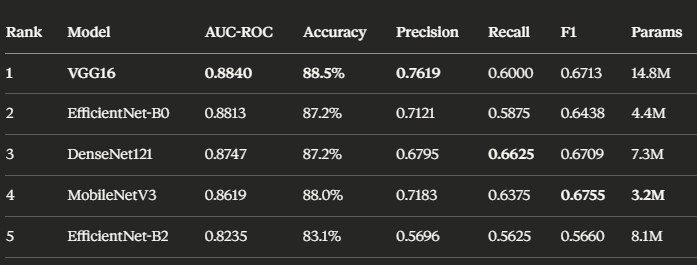

### Even though having 14.8M parameters how this model is performing well?

The short answer: we only fine-tuned 14.8M parameters, not 138M.

When you use include_top=False, VGG16's original massive head — two Dense(4096) layers totalling ~119M parameters — is completely removed. What remains is just the convolutional backbone at 14.7M parameters. That's actually comparable to DenseNet121 (7.3M) and not extreme at all.

Why VGG16's convolutions work so well for geoglyphs specifically:

1. Pure 3×3 geometry detection.
VGG16 uses exclusively 3×3 filters stacked very deep. This forces the network to learn progressively larger geometric patterns — edges → corners → curves → shapes. Geoglyphs are almost entirely composed of these exact primitives: straight lines, right angles, circular arcs. VGG16's architecture is almost accidentally perfect for this task.

2. No architectural shortcuts to distract it.
ResNet has skip connections. DenseNet has dense shortcuts. EfficientNet has squeeze-excitation attention. These all help on complex natural image tasks. But geoglyphs are simple geometric patterns — VGG16's "dumb" sequential design forces every layer to learn progressively richer geometric representations without any shortcuts. It can't cheat.

3. GAP saved it from itself.
The original VGG16 head (Flatten → Dense(4096) → Dense(4096)) would have been catastrophic — 119M parameters on 371 positives. By replacing it with GlobalAveragePooling + Dense(256), we reduced the head to 132K trainable parameters in Stage 1. This is actually the leanest head of all 5 models. The architecture's notorious weakness was neutralised by our design choice.

4. Dropout(0.4) did heavy lifting.
40% neuron dropout in the head combined with the small Dense(256) created very strong regularisation. VGG16's backbone features are rich enough that even a heavily regularised small head could extract good geoglyph representations.

**The honest caveat though**:
VGG16's recall (0.6000) is still below DenseNet (0.6625) and MobileNetV3 (0.6375). For Walker Lab's actual deployment — where finding every geoglyph matters most — DenseNet121 remains the practical recommendation. VGG16 leads the benchmark table but isn't necessarily the best field tool.